In [108]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import nflreadpy as nfl

# Define the years to import
yrs = range(2016, 2025, 2)  # Adjust the range as needed
#yrs = 2022

# Play-by-Play Data
pbp = nfl.load_pbp(yrs)
cols = ['game_id', 'play_id', 'home_team', 'away_team', 'posteam', 'play_type', 'down', 'ydstogo', 'qtr', 'shotgun', 'no_huddle', 'qb_scramble', 'pass_length', 
        'pass_location', 'yards_after_catch', 'run_gap', 'wp', 'ep', 'xpass', 'kick_distance']
pbp = pbp[cols].to_pandas()
pbp = pbp.sample(frac=0.75, random_state=99)

# Schedules
schedules = nfl.load_schedules(yrs)
schedules = schedules[['game_id', 'away_coach', 'home_coach']].to_pandas()

# Participant
participation = nfl.load_participation(yrs)
participation = participation[['nflverse_game_id', 'play_id', 'offense_formation', 'offense_personnel', 'defenders_in_box', 'defense_personnel', 'number_of_pass_rushers', 'route', 
                               'defense_man_zone_type', 'defense_coverage_type']].to_pandas()

data = pd.merge(pbp, participation, left_on=['game_id', 'play_id'], right_on=['nflverse_game_id', 'play_id'], how='left')
data = pd.merge(data, schedules, on='game_id', how='left')

In [109]:
# Rows in sampled data
print(f"Rows in sampled data: {len(data)}")

Rows in sampled data: 181043


In [110]:
field_goal_attempts = data[data['play_type'] == 'field_goal']
data = data[data['play_type'].isin(['pass', 'run'])]
data.head()

,game_id,play_id,home_team,away_team,posteam,play_type,down,ydstogo,qtr,shotgun,...,offense_formation,offense_personnel,defenders_in_box,defense_personnel,number_of_pass_rushers,route,defense_man_zone_type,defense_coverage_type,away_coach,home_coach
0,2024_09_IND_MIN,1014.0,MIN,IND,MIN,pass,3.0,16.0,2.0,1.0,...,SHOTGUN,"1 C, 2 G, 1 QB, 1 RB, 2 T, 1 TE, 3 WR",4.0,"3 CB, 3 DE, 1 DT, 2 FS, 1 OLB, 1 SS",4.0,SCREEN,MAN_COVERAGE,COVER_1,Shane Steichen,Kevin O'Connell
1,2024_14_CAR_PHI,1474.0,PHI,CAR,CAR,run,2.0,6.0,2.0,0.0,...,UNDER CENTER,"4 G, 1 QB, 1 RB, 2 T, 1 TE, 2 WR",7.0,"2 CB, 1 DE, 3 DT, 1 FS, 1 ILB, 2 OLB, 1 SS",0.0,,,None,Dave Canales,Nick Sirianni
3,2018_05_BAL_CLE,4584.0,CLE,BAL,BAL,pass,2.0,12.0,5.0,1.0,...,EMPTY,"1 RB, 1 TE, 3 WR",5.0,"3 DL, 4 LB, 4 DB",3.0,SCREEN,ZONE_COVERAGE,COVER_2,John Harbaugh,Hue Jackson
4,2022_12_ATL_WAS,1821.0,WAS,ATL,WAS,run,3.0,1.0,3.0,0.0,...,SINGLEBACK,"1 RB, 1 TE, 3 WR",6.0,"2 DL, 4 LB, 5 DB",NaN,None,None,None,Arthur Smith,Ron Rivera
5,2018_15_PHI_LA,408.0,LA,PHI,LA,run,2.0,4.0,1.0,0.0,...,SINGLEBACK,"1 RB, 1 TE, 3 WR",7.0,"4 DL, 2 LB, 5 DB",NaN,None,None,None,Doug Pederson,Sean McVay


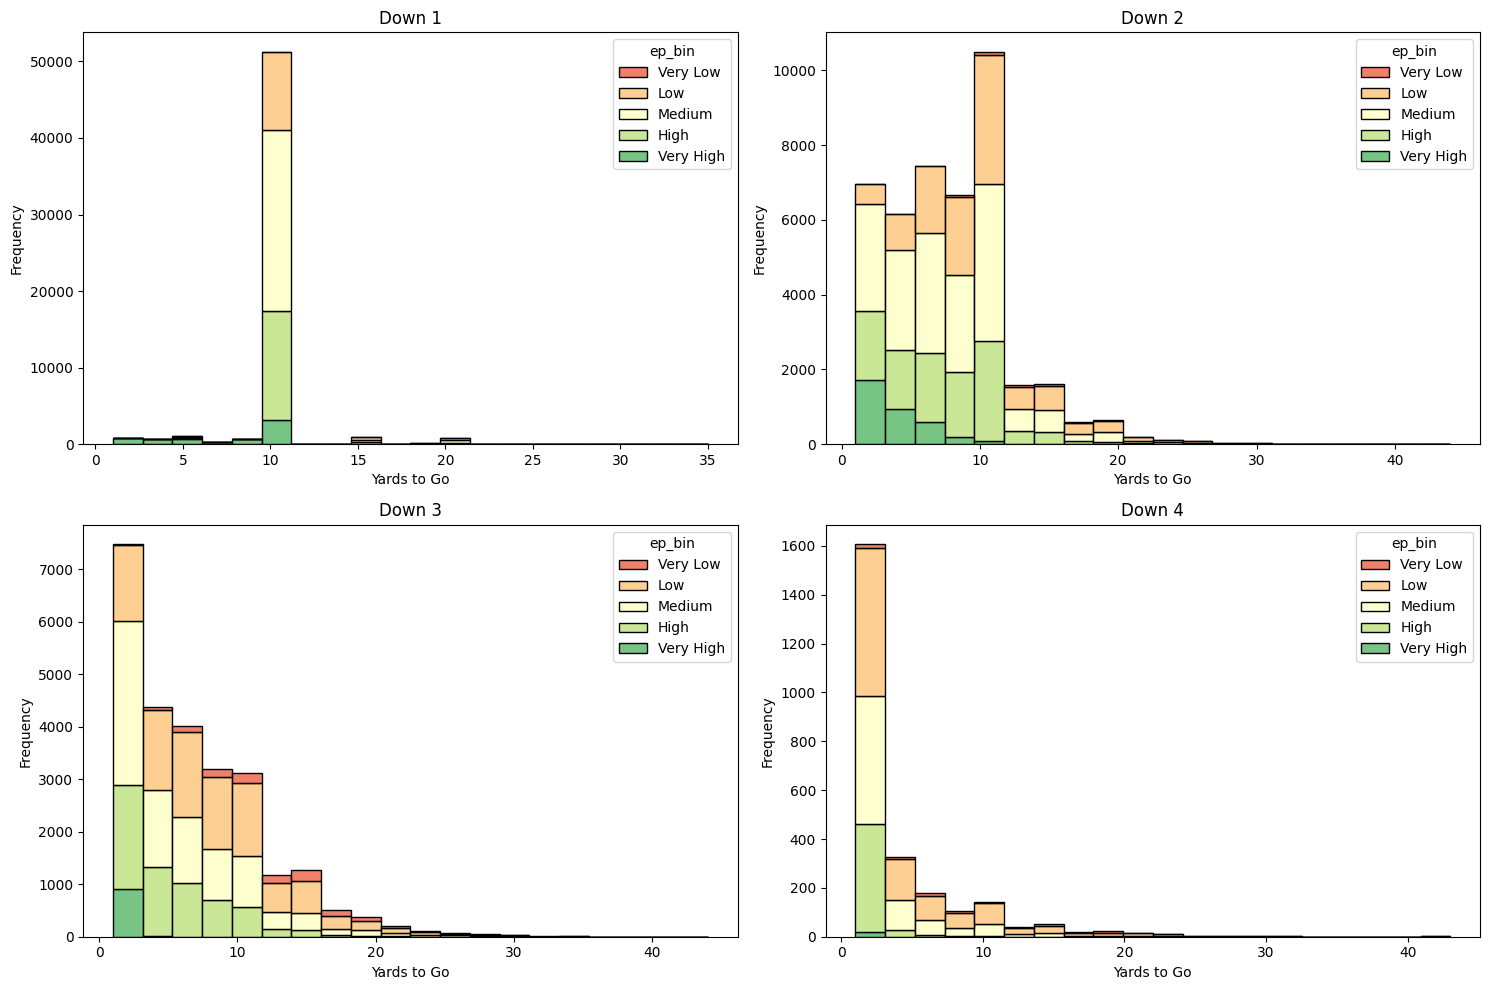

In [111]:
# Create binned ep categories
data['ep_bin'] = pd.cut(data['ep'], bins=5, labels=['Very Low', 'Low', 'Medium', 'High', 'Very High'])

# Create win percentage bin
data['wp_bin'] = pd.cut(data['wp'], bins=5, labels=['Very Low', 'Low', 'Medium', 'High', 'Very High'])

# Define first_quarter bin column
data['quarter_bin'] = np.where(data['qtr'] == 1, 'first_quarter', 'not_first_quarter')

# Distance; down interaction
data['dist_down'] = data['ydstogo'] * data['down']
data['dist_down_log'] = np.log1p(data['dist_down'])
data['dist_down_bin'] = pd.cut(data['dist_down_log'], bins=5, labels=['Very Low', 'Low', 'Medium', 'High', 'Very High'])

# Subplots for each down
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for i, down in enumerate([1, 2, 3, 4]):
    ax = axes[i//2, i%2]
    down_data = data[data['down'] == down]
    sns.histplot(data=down_data, x='ydstogo', hue='ep_bin', bins=20, ax=ax, palette='RdYlGn', multiple='stack')
    ax.set_title(f'Down {down}')
    ax.set_xlabel('Yards to Go')
    ax.set_ylabel('Frequency')
plt.tight_layout()
plt.show()

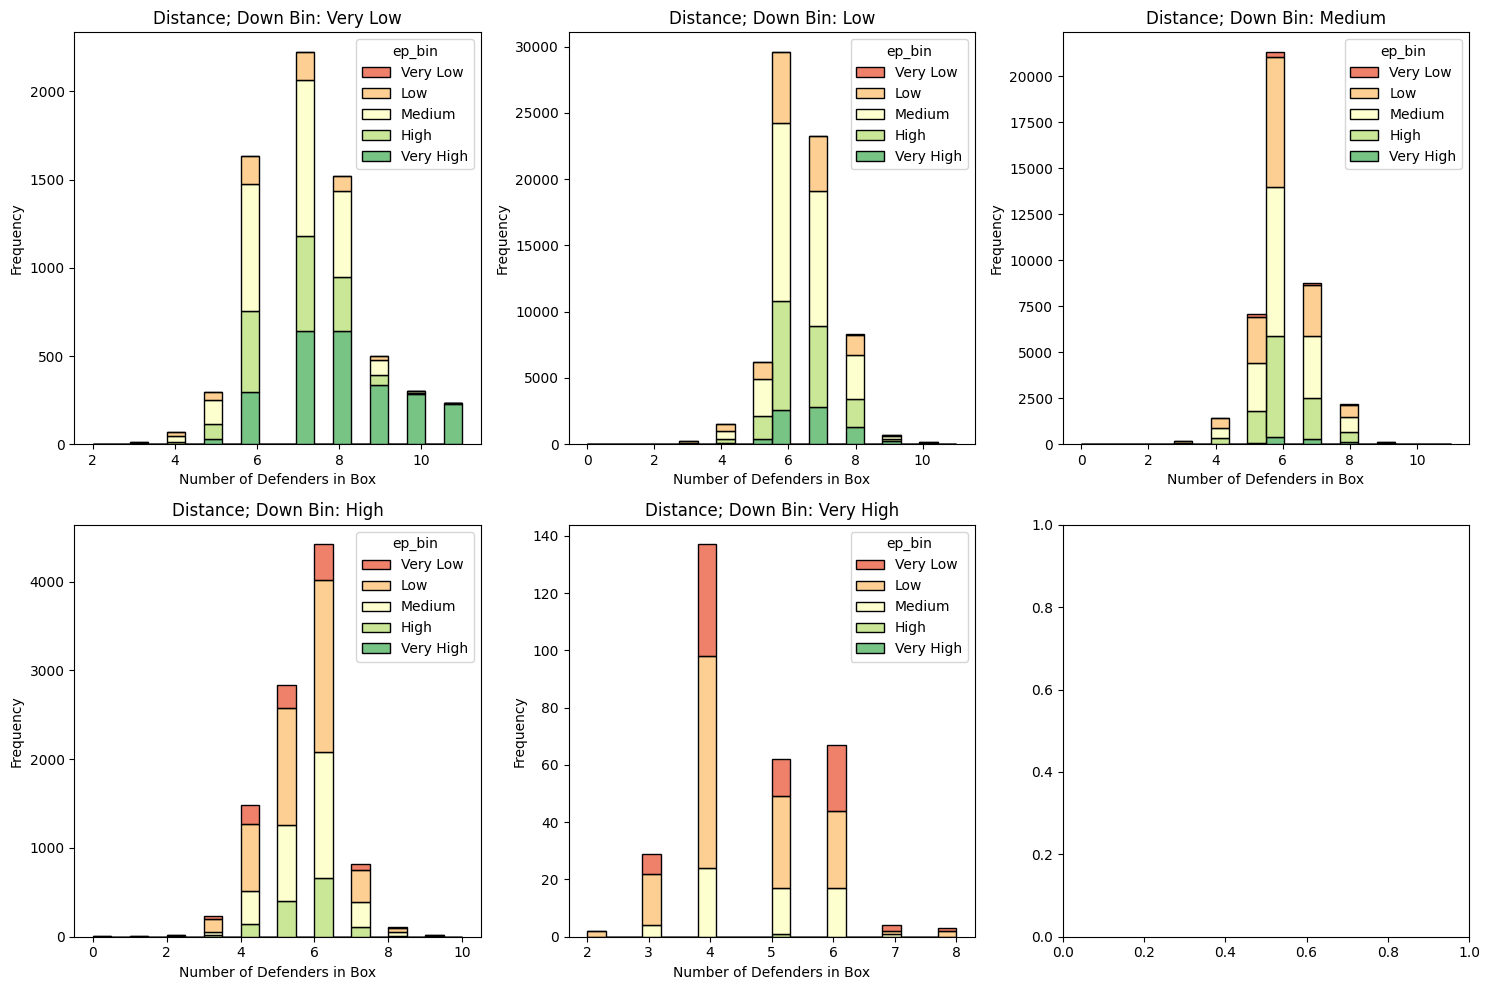

In [112]:
# Subplots for each epa bin
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for i, bin in enumerate(['Very Low', 'Low', 'Medium', 'High', 'Very High']):
    ax = axes[i//3, i%3]
    epa_bin_data = data[data['dist_down_bin'] == bin]
    sns.histplot(data=epa_bin_data, x='defenders_in_box', hue='ep_bin', bins=20, ax=ax, palette='RdYlGn', multiple='stack')
    ax.set_title(f'Distance; Down Bin: {bin}')
    ax.set_xlabel('Number of Defenders in Box')
    ax.set_ylabel('Frequency')
plt.tight_layout()
plt.show()

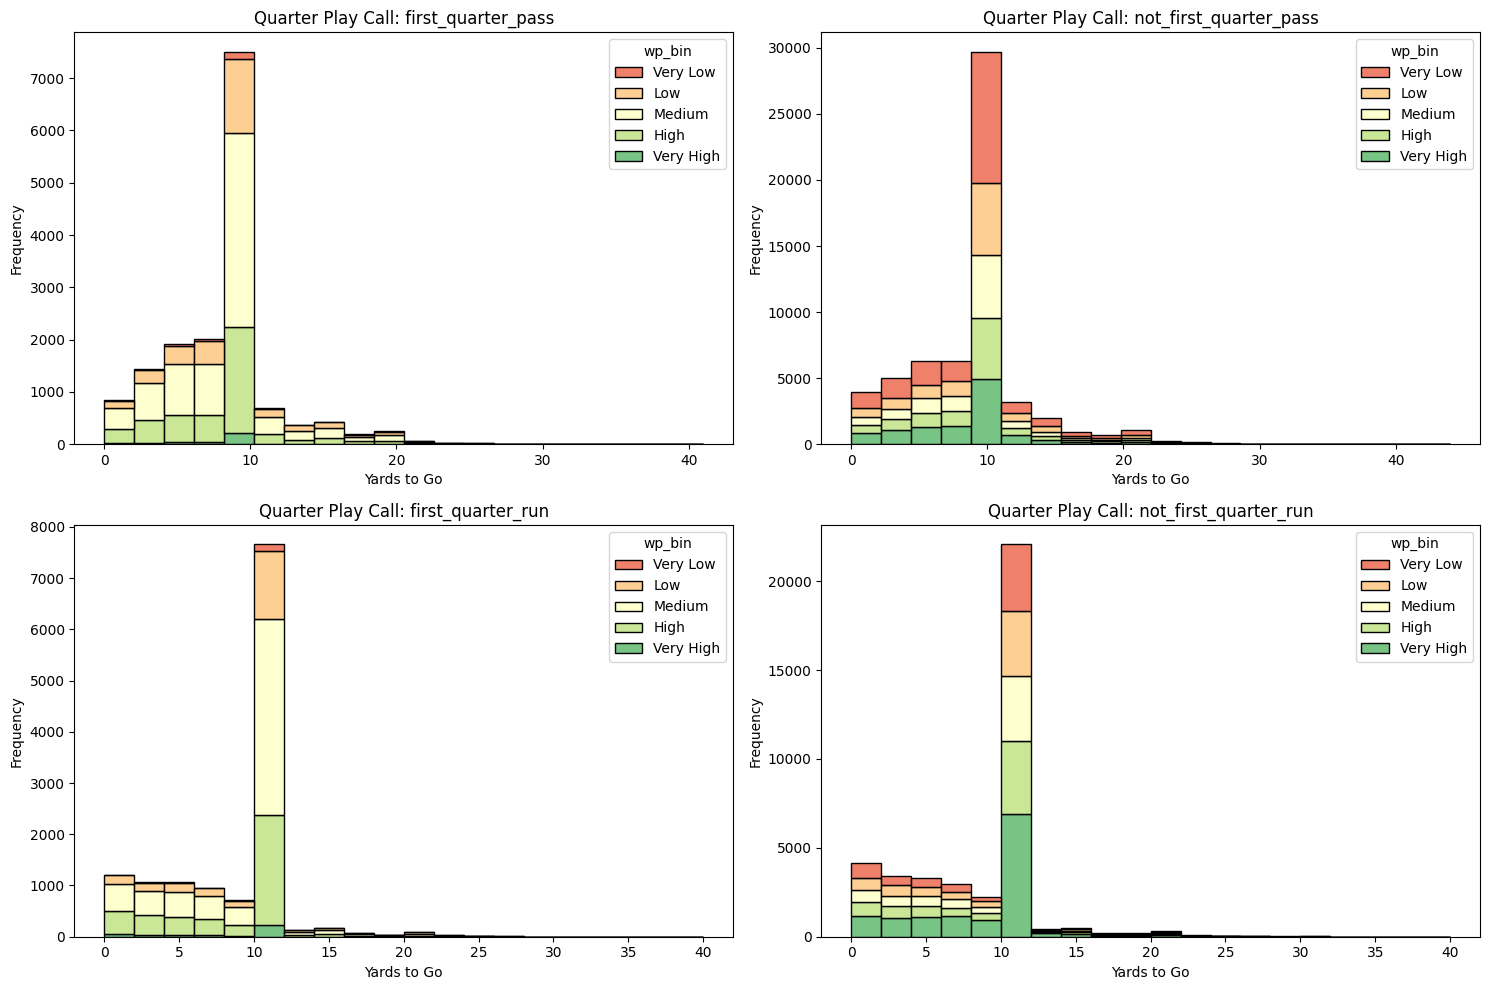

In [113]:
# Create bin for quarter_bin against play_type
data['quarter_play_call'] = np.where(
    data['qtr'] == 1,
    'first_quarter_' + data['play_type'],
    'not_first_quarter_' + data['play_type']
)

# Subplots for each quarter_play_call
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for i, quarter_play_call in enumerate(['first_quarter_pass', 'not_first_quarter_pass', 'first_quarter_run', 'not_first_quarter_run']):
    ax = axes[i//2, i%2]
    quarter_play_call_data = data[data['quarter_play_call'] == quarter_play_call]
    sns.histplot(data=quarter_play_call_data, x='ydstogo', hue='wp_bin', bins=20, ax=ax, palette='RdYlGn', multiple='stack')
    ax.set_title(f'Quarter Play Call: {quarter_play_call}')
    ax.set_xlabel('Yards to Go')
    ax.set_ylabel('Frequency')
plt.tight_layout()
plt.show()

# Build Expectations of the following features
'shotgun', 
'no_huddle', 
'qb_scramble', 
'pass_length',
'pass_location', 
'yards_after_catch', 
'defenders_in_box',
'number_of_pass_rushers', 
'offense_formation', 
'route', 
'run_gap', 
'defense_man_zone_type', 
'defense_coverage_type'

In [114]:
# Create train and test sets for runs and passes
run_mask = data['play_type'] == 'run'
pass_mask = data['play_type'] == 'pass'
train_idx = data['play_id'] < data['play_id'].quantile(0.8)
off_features = ['ep_bin', 'wp_bin', 'dist_down_bin', 'quarter_bin', 'play_type', 'shotgun', 'no_huddle', 'defenders_in_box']
def_features = ['ep_bin', 'wp_bin', 'dist_down_bin', 'quarter_bin', 'play_type', 'shotgun', 'no_huddle', 'offense_personnel']

# Convert categorical features to category dtype
for col in off_features + def_features:
    data.loc[:, col] = data[col].astype('category')

C:\Users\Jack\AppData\Local\Temp\ipykernel_19928\3797729593.py:10: DeprecationWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  data.loc[:, col] = data[col].astype('category')
C:\Users\Jack\AppData\Local\Temp\ipykernel_19928\3797729593.py:10: DeprecationWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain the old behavior, use either `df[df.columns[i]] = newvals` or, if columns are non-unique, `df.isetitem(i, newvals)`
  data.loc[:, col] = data[col].astype('category')
C:\Users\Jack\AppData\Local\Temp\ipykernel_19928\3797729593.py:10: DeprecationWarning: In a future version, `df.iloc[:, i] = newvals` will attempt to set the values inplace instead of always setting a new array. To retain th

In [115]:
import joblib
import pandas as pd
import xgboost as xgb
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error, r2_score, f1_score

class NFLExpectationRegistry:
    """A container to manage, save, and load multiple NFL expectation feature models."""
    def __init__(self):
        self.models = {}
        self.encoders = {}

    def add_model(self, target_name, model, encoder=None):
        self.models[target_name] = model
        self.encoders[target_name] = encoder

    def save_registry(self, path=r'C:\Users\Jack\Documents\GitHub\FFInsights\schemes_expectation_models.joblib'):
        joblib.dump({'models': self.models, 'encoders': self.encoders}, path)

    def load_registry(self, path=r'C:\Users\Jack\Documents\GitHub\FFInsights\schemes_expectation_models.joblib'):
        data = joblib.load(path)
        self.models = data['models']
        self.encoders = data['encoders']

In [116]:
def train_expectation_model(X, y, model_class='classifier', params=None):
    # 1. Clean data locally - drop NaNs from BOTH X and y
    valid_idx = y.dropna().index
    valid_idx = valid_idx.intersection(X.dropna().index)
    X_local, y_local = X.loc[valid_idx].copy(), y.loc[valid_idx].copy()
    
    # 2. Critical: Explicitly handle categoricals for XGBoost
    for col in X_local.select_dtypes(['object', 'string']).columns:
        X_local[col] = X_local[col].astype('category')

    # 3. Label Encoding for Classifiers
    le = None
    if model_class == 'classifier':
        le = LabelEncoder()
        y_local = le.fit_transform(y_local)

    # 4. Fit Model
    if model_class == 'regressor':
        model = xgb.XGBRegressor(**(params or {}), enable_categorical=True)
    else:
        model = xgb.XGBClassifier(**(params or {}), enable_categorical=True)
    
    model.fit(X_local, y_local)
    pred_train = model.predict(X_local)
    
    # Get test indices - clean BOTH X_test and y_test
    test_idx = X.index.difference(X_local.index)
    X_test = X.loc[test_idx].dropna()
    y_test = y.loc[X_test.index].dropna()
    
    # Ensure X_test and y_test are aligned after dropping NaNs
    X_test = X_test.loc[y_test.index]
    
    if len(X_test) > 0:
        pred_test = model.predict(X_test)
    else:
        pred_test = []
    
    target_name = y.name if hasattr(y, 'name') else 'target'
    if model_class == 'regressor':
        print(f"Train MSE for {target_name}:", round(mean_squared_error(y_local, pred_train), 3), "R2:", round(r2_score(y_local, pred_train), 4))
        if len(pred_test) > 0:
            print(f"Test MSE for {target_name}:", round(mean_squared_error(y_test, pred_test), 3), "R2:", round(r2_score(y_test, pred_test), 4))
    else:
        print(f"Train F1 (weighted) {target_name}: {f1_score(y_local, pred_train, average='weighted'):.4f}")
        if len(pred_test) > 0:
            print(f"Test F1 (weighted) {target_name}: {f1_score(y_test, pred_test, average='weighted'):.4f}")
    return model, le

# Training

In [26]:
# Train models for each expectation feature and store in registry
registry = NFLExpectationRegistry()

# Define your "Task List"
tasks = [
    ('defenders_in_box', data[def_features], 'regressor', None),
    ('number_of_pass_rushers', data[pass_mask][def_features], 'regressor', pass_mask),
    ('defense_coverage_type', data[pass_mask][def_features], 'classifier', pass_mask),
    ('defense_man_zone_type', data[pass_mask][def_features], 'classifier', pass_mask),
    ('offense_formation', data[off_features], 'classifier', None),
    ('offense_personnel', data[off_features], 'classifier', None),
    ('route', data[pass_mask][off_features], 'classifier', pass_mask),
    ('run_gap', data[run_mask][off_features], 'classifier', run_mask),
    ('shotgun',  data[pass_mask][off_features], 'classifier', pass_mask),
    ('qb_scramble', data[run_mask][off_features], 'classifier', run_mask),
    ('no_huddle', data[def_features], 'classifier', None),
    ('pass_length', data[pass_mask][def_features], 'classifier', pass_mask),
    ('pass_location', data[pass_mask][def_features], 'classifier', pass_mask),
    ('yards_after_catch', data[pass_mask][def_features], 'regressor', pass_mask),
]

for name, features, mtype, mask in tasks:
    target = data[name] if mask is None else data[mask][name]
    m, encoder = train_expectation_model(features, target, model_class=mtype)
    registry.add_model(name, m, encoder)

# Save everything for the prod notebook
registry.save_registry(r'C:\Users\Jack\Documents\GitHub\FFInsights\schemes_expectation_models.joblib')

Train MSE for defenders_in_box: 0.585 R2: 0.4868


KeyboardInterrupt: 

In [117]:
# Load registry to make predictions
registry = NFLExpectationRegistry()
registry.load_registry(r'C:\Users\Jack\Documents\GitHub\FFInsights\schemes_expectation_models.joblib')

data['xdefenders_in_box'] = registry.models['defenders_in_box'].predict(data[registry.models['defenders_in_box'].get_booster().feature_names])
data['xnumber_of_pass_rushers'] = registry.models['number_of_pass_rushers'].predict(data[registry.models['number_of_pass_rushers'].get_booster().feature_names])
data['xdefense_coverage_type'] = registry.models['defense_coverage_type'].predict(data[registry.models['defense_coverage_type'].get_booster().feature_names])
data['xdefense_man_zone_type'] = registry.models['defense_man_zone_type'].predict_proba(data[registry.models['defense_man_zone_type'].get_booster().feature_names])[:, 1] # Chance of man coverage
data['xoffense_formation'] = registry.models['offense_formation'].predict(data[registry.models['offense_formation'].get_booster().feature_names])
data['xoffense_personnel'] = registry.models['offense_personnel'].predict(data[registry.models['offense_personnel'].get_booster().feature_names])
data['xroute'] = registry.models['route'].predict(data[registry.models['route'].get_booster().feature_names])
data['xrun_gap'] = registry.models['run_gap'].predict(data[registry.models['run_gap'].get_booster().feature_names])
data['xshotgun'] = registry.models['shotgun'].predict_proba(data[registry.models['shotgun'].get_booster().feature_names])[:, 1] # Chance of shotgun is true
data['xqb_scramble'] = registry.models['qb_scramble'].predict_proba(data[registry.models['qb_scramble'].get_booster().feature_names])[:, 1] # Chance of qb scramble is True
data['xno_huddle'] = registry.models['no_huddle'].predict_proba(data[registry.models['no_huddle'].get_booster().feature_names])[:, 1] # Chance of no huddle is true
data['xpass_length'] = registry.models['pass_length'].predict_proba(data[registry.models['pass_length'].get_booster().feature_names])[:, 1] # Chance pass is "short"
data['xpass_location'] = registry.models['pass_location'].predict(data[registry.models['pass_location'].get_booster().feature_names])
data['xyards_after_catch'] = registry.models['yards_after_catch'].predict(data[registry.models['yards_after_catch'].get_booster().feature_names])

#data['xdefenders_in_box'] = registry.encoders['defenders_in_box'].inverse_transform(data['xdefenders_in_box'].round().astype(int))
#data['xnumber_of_pass_rushers'] = registry.encoders['number_of_pass_rushers'].inverse_transform(data['xnumber_of_pass_rushers'].round().astype(int))
data['xdefense_coverage_type'] = registry.encoders['defense_coverage_type'].inverse_transform(data['xdefense_coverage_type'].astype('category'))
data.rename(columns={'xdefense_man_zone_type': 'xdefense_man_type'}, inplace=True)
data['xoffense_formation'] = registry.encoders['offense_formation'].inverse_transform(data['xoffense_formation'].astype('category'))
data['xoffense_personnel'] = registry.encoders['offense_personnel'].inverse_transform(data['xoffense_personnel'].astype('category'))
data['xroute'] = registry.encoders['route'].inverse_transform(data['xroute'].astype('category'))
data['xrun_gap'] = registry.encoders['run_gap'].inverse_transform(data['xrun_gap'].astype('category'))
#data.rename(columns={'xshotgun': 'xshotgun'}, inplace=True)
#data.rename(columns={'xqb_scramble': 'xqb_scramble'}, inplace=True)
#data.rename(columns={'xno_huddle': 'xno_huddle'}, inplace=True)
data.rename(columns={'xpass_length': 'xpass_length_short'}, inplace=True)
data['xpass_location'] = registry.encoders['pass_location'].inverse_transform(data['xpass_location'].astype('category'))
#data['xyards_after_catch'] = registry.encoders['yards_after_catch'].inverse_transform(data['xyards_after_catch'].round().astype(int))

data[['xpass', 'xdefenders_in_box', 'xnumber_of_pass_rushers', 'xdefense_coverage_type', 'xdefense_man_type', 
      'xshotgun', 'xno_huddle', 'xqb_scramble', 'xpass_length_short', 'xpass_location', 'xyards_after_catch', 'xoffense_formation', 'xoffense_personnel', 'xroute', 'xrun_gap']].head()

,xpass,xdefenders_in_box,xnumber_of_pass_rushers,xdefense_coverage_type,xdefense_man_type,xshotgun,xno_huddle,xqb_scramble,xpass_length_short,xpass_location,xyards_after_catch,xoffense_formation,xoffense_personnel,xroute,xrun_gap
0,0.946803,5.622593,4.940221,COVER_3,0.208132,0.999977,0.000012,0.177255,0.831225,middle,20.112165,SHOTGUN,"3 G, 1 QB, 1 RB, 2 T, 1 TE, 3 WR",HITCH,guard
1,0.600531,6.440951,4.217174,COVER_0,0.819279,0.000106,0.000012,0.029787,0.947225,middle,5.381569,SINGLEBACK,"1 RB, 2 TE, 2 WR",SCREEN,end
3,0.871425,6.163535,4.327809,COVER_2,0.301046,0.999977,0.000012,0.330919,0.825712,left,5.476466,SHOTGUN,"3 G, 1 QB, 1 RB, 2 T, 1 TE, 3 WR",OUT,guard
4,0.203925,6.737622,4.477553,COVER_1,0.672673,0.000106,0.000012,0.003241,0.665165,right,5.827467,SINGLEBACK,"1 C, 1 FB, 2 G, 1 QB, 1 RB, 2 T, 1 TE, 2 WR",CROSS,guard
5,0.482318,6.512872,4.259946,COVER_2,0.272601,0.000106,0.000012,0.015815,0.702293,left,6.411394,SINGLEBACK,"2 RB, 1 TE, 2 WR",CROSS,tackle


# Over-Expectation Calculations

In [118]:
# Group by ['ep_bin', 'dist_down_bin', 'quarter_bin', 'play_type'] to calculate frequency counts
strat_keys = ['ep_bin', 'dist_down_bin', 'quarter_bin', 'play_type']
#first_quarter = data[data['quarter_bin'] == 'first_quarter']
a = data.groupby(strat_keys).size().reset_index(name='count').sort_values('count', ascending=False)
a['Cumulative_Percent'] = a['count'].cumsum() / a['count'].sum() * 100

# Save strat_keys when cumulative_percent is below 75%
selected_strat_keys = a[a['Cumulative_Percent'] < 75][strat_keys] # Ends up being top 10

# Filter original data to only include rows that match the selected strat_keys
strat_keys_filtered = pd.merge(data, selected_strat_keys, on=strat_keys, how='inner')

# Print unique strat keys
print("Unique strat keys that cover 75% of plays:")
print(strat_keys_filtered[strat_keys].drop_duplicates())

Unique strat keys that cover 75% of plays:
          ep_bin dist_down_bin        quarter_bin play_type
0            Low          High  not_first_quarter      pass
3227      Medium        Medium  not_first_quarter      pass
11965     Medium           Low      first_quarter       run
15817     Medium           Low  not_first_quarter      pass
28207     Medium           Low  not_first_quarter       run
39301        Low        Medium  not_first_quarter      pass
47132        Low           Low  not_first_quarter      pass
52691     Medium        Medium  not_first_quarter       run
55999       High        Medium  not_first_quarter      pass
61890  Very High           Low  not_first_quarter       run
65163       High           Low  not_first_quarter       run
72496       High           Low  not_first_quarter      pass
79666        Low           Low  not_first_quarter       run
84300  Very High           Low  not_first_quarter      pass
86649     Medium           Low      first_quarter      pa

In [119]:
data = strat_keys_filtered.copy()

# Value counts for categorical predictions ['xoffense_formation', 'xoffense_personnel', 'xroute', 'xrun_gap', 'xdefense_coverage_type']
print("Value counts for xdefense_coverage_type:")
print(data['xdefense_coverage_type'].value_counts())
print("\nValue counts for xoffense_formation:")
print(data['xoffense_formation'].value_counts())
print("\nValue counts for xoffense_personnel:")
print(data['xoffense_personnel'].value_counts())
print("\nValue counts for xroute:")
print(data['xroute'].value_counts())
print("\nValue counts for xrun_gap:")
print(data['xrun_gap'].value_counts())

Value counts for xdefense_coverage_type:
COVER_3    39061
COVER_1    21786
COVER_2    16691
COVER_4    10494
COVER_0     4766
2_MAN       1605
BLOWN        296
COMBO        153
COVER_6       55
COVER_9       15
Name: xdefense_coverage_type, dtype: int64

Value counts for xoffense_formation:
SHOTGUN         64268
SINGLEBACK      29616
I_FORM            447
UNDER CENTER      335
EMPTY             136
JUMBO             110
WILDCAT             7
PISTOL              3
Name: xoffense_formation, dtype: int64

Value counts for xoffense_personnel:
1 RB, 2 TE, 2 WR                               19170
2 RB, 1 TE, 2 WR                               15252
1 RB, 0 TE, 4 WR                                7420
1 C, 3 G, 1 QB, 1 RB, 1 T, 1 TE, 3 WR           6173
1 C, 1 G, 1 QB, 1 RB, 3 T, 2 TE, 2 WR           5465
2 RB, 2 TE, 1 WR                                4636
1 C, 2 G, 1 QB, 1 RB, 2 T, 2 TE, 2 WR           4138
1 RB, 3 TE, 1 WR                                3958
2 C, 1 G, 1 QB, 1 RB, 2 T, 1 TE

In [ ]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

data = strat_keys_filtered.copy()

# 1. BATCH ASSIGNMENT (Avoids fragmentation)
new_cols = {}

# Coaches
new_cols['offensive_coach'] = np.where(data['posteam'] == data['home_team'], data['home_coach'], data['away_coach'])
new_cols['defensive_coach'] = np.where(data['posteam'] == data['home_team'], data['away_coach'], data['home_coach'])

# Binary Actuals
new_cols['is_shotgun'] = (data['shotgun'] == 1).astype(int)
new_cols['is_no_huddle'] = (data['no_huddle'] == 1).astype(int)
new_cols['is_qb_scramble'] = (data['qb_scramble'] == 1).astype(int)
new_cols['is_pass_short'] = (data['pass_length'] == 'short').astype(int)
new_cols['is_man_coverage'] = (data['defense_man_zone_type'] == 'man').astype(int)

# Simple ROE Calculations
new_cols['defenders_in_box_oe'] = data['defenders_in_box'].astype(float) - data['xdefenders_in_box'].astype(float)
new_cols['pass_rushers_oe'] = data['number_of_pass_rushers'].astype(float) - data['xnumber_of_pass_rushers'].astype(float)
new_cols['yac_oe'] = data['yards_after_catch'].astype(float) - data['xyards_after_catch'].astype(float)
new_cols['pass_oe'] = data['xpass'].astype(float) - (data['play_type'] == 'pass').astype(int)

new_cols['shotgun_oe'] = new_cols['is_shotgun'] - data['xshotgun'].astype(float)
new_cols['no_huddle_oe'] = new_cols['is_no_huddle'] - data['xno_huddle'].astype(float)
new_cols['scramble_oe'] = new_cols['is_qb_scramble'] - data['xqb_scramble'].astype(float)
new_cols['pass_length_short_oe'] = new_cols['is_pass_short'] - data['xpass_length_short'].astype(float)
new_cols['man_coverage_oe'] = new_cols['is_man_coverage'] - data['xdefense_man_type'].astype(float)

# Create dictionary to save categories for each categorical variable
categories_dict = {
    'defense_coverage_type': ['COVER_3', 'COVER_1', 'COVER_2', 'COVER_0'],
    'offense_formation': ['SHOTGUN', 'SINGLEBACK'],
    'offense_personnel': ['1 RB, 2 TE, 2 WR', '2 RB, 1 TE, 2 WR', '2 RB, 2 TE, 1 WR', '1 RB, 3 TE, 1 WR', '2 RB, 0 TE, 3 WR'],
    'route': ['CROSS', 'HITCH', 'FLAT', 'GO', 'SCREEN'],
    'run_gap': ['guard', 'end', 'tackle']
}

# Initialize a container for our new OE columns
oe_results = {}

for col, target_categories in categories_dict.items():
    xcol = f'x{col}' # The expectation column
    
    for cat in target_categories:
        # Define the column name
        oe_name = f"{col}_{cat.replace(' ', '_').lower()}_oe"
        
        # ACTUAL: 1 if the play was this category, else 0
        actual = (data[col] == cat).astype(int)
        
        # EXPECTED: 1 if the model predicted this category, else 0
        expected = (data[xcol] == cat).astype(int)
        
        # OE = Observed - Predicted
        # Result is 1 (Surprise usage), -1 (Surprise avoidance), or 0 (As expected)
        oe_results[oe_name] = actual - expected

# Join all new columns to the main dataframe in one single operation
data = pd.concat([data, pd.DataFrame(oe_results, index=data.index)], axis=1)

# Remove duplicates if cell was re-run
data = data.loc[:, ~data.columns.duplicated()].copy()

# Assign new columns directly (safe for reruns)
for k, v in new_cols.items():
    data[k] = v

# AGGREGATION (Macro-Averaging without game_id overhead)
off_roe_cols = [c for c in data.columns if c.endswith('_oe') and not c.startswith('defense_')]
def_roe_cols = [c for c in data.columns if c.endswith('_oe') and not c.startswith('offense_')]

# Ensure situational bins don't have stray NaNs before grouping
strat_keys = ['ep_bin', 'dist_down_bin', 'play_type']

# Stage 1: Situational Averaging 
# observed=True is CRITICAL to prevent row explosion
off_strat = (data.groupby(['offensive_coach', 'game_id'] + strat_keys, observed=True)[off_roe_cols]
             .mean()
             .reset_index())

# Stage 2: Coach Identity
# We use numeric_only=True and handle NaNs
# Some columns (like yac_oe) might still have NaNs if a coach had NO successful passes in a bin
off_scheme = (off_strat.groupby(['offensive_coach', 'game_id'], observed=True)[off_roe_cols]
              .mean() # This will ignore NaNs within the columns
              .reset_index())

# Repeat for Defense
def_strat = (data.groupby(['defensive_coach', 'game_id'] + strat_keys, observed=True)[def_roe_cols]
             .mean()
             .reset_index())

def_scheme = (def_strat.groupby(['defensive_coach', 'game_id'], observed=True)[def_roe_cols]
              .mean()
              .reset_index())

In [127]:
off_scheme.head()

,offensive_coach,game_id,offense_formation_shotgun_oe,offense_formation_singleback_oe,"offense_personnel_1_rb,_2_te,_2_wr_oe","offense_personnel_2_rb,_1_te,_2_wr_oe","offense_personnel_2_rb,_2_te,_1_wr_oe","offense_personnel_1_rb,_3_te,_1_wr_oe","offense_personnel_2_rb,_0_te,_3_wr_oe",route_cross_oe,...,run_gap_tackle_oe,defenders_in_box_oe,pass_rushers_oe,yac_oe,pass_oe,shotgun_oe,no_huddle_oe,scramble_oe,pass_length_short_oe,man_coverage_oe
0,Adam Gase,2016_01_MIA_SEA,-0.238095,-0.047619,-0.142857,-0.238095,-0.142857,0.047619,0.000000,-0.047619,...,-0.047619,-0.279335,-0.040045,6.643301,-0.072747,-0.000014,-0.000012,-0.178515,-0.437877,-0.323393
1,Adam Gase,2016_02_MIA_NE,-0.045455,-0.022727,-0.090909,-0.113636,0.000000,-0.022727,0.022727,0.068182,...,-0.136364,-0.035249,-0.111348,-1.589475,0.006188,0.000006,0.000061,-0.114658,-0.082504,-0.240940
2,Adam Gase,2016_03_CLE_MIA,-0.129032,-0.032258,-0.032258,-0.096774,0.000000,-0.032258,-0.032258,-0.096774,...,-0.258065,-0.380881,0.073993,-1.937645,-0.008846,-0.000031,0.000033,-0.145816,-0.321309,-0.361872
3,Adam Gase,2016_04_MIA_CIN,-0.160000,-0.040000,0.040000,-0.160000,0.000000,-0.080000,-0.080000,-0.120000,...,-0.040000,-0.211611,-0.268465,0.216344,0.125811,-0.000018,-0.000013,-0.155386,-0.229605,-0.288263
4,Adam Gase,2016_05_TEN_MIA,0.000000,-0.043478,-0.086957,-0.173913,0.000000,0.043478,-0.086957,0.043478,...,0.000000,0.187966,0.130889,0.931524,-0.016033,-0.000010,-0.000006,-0.088770,-0.364874,-0.315349


# Auto Correlation of OE Variables

In [128]:
# Sort offense and defense schemes by game_id
off_scheme = off_scheme.sort_values('game_id')
def_scheme = def_scheme.sort_values('game_id')

# Calculate future averages for each feature column
off_features = [col for col in off_scheme.columns if col not in ['offensive_coach', 'defensive_coach', 'game_id']]
def_features = [col for col in def_scheme.columns if col not in ['offensive_coach', 'defensive_coach', 'game_id']]
for feature in off_features:
    off_scheme[f'future_{feature}'] = off_scheme.groupby('offensive_coach')[feature].transform(lambda x: x.shift(-1).rolling(window=30, min_periods=1).mean())
for feature in def_features:
    def_scheme[f'future_{feature}'] = def_scheme.groupby('defensive_coach')[feature].transform(lambda x: x.shift(-1).rolling(window=30, min_periods=1).mean())

# Calculate auto correlation between current and future features for offense and defense
from scipy.stats import pearsonr
off_correlations = {}
def_correlations = {}
for feature in off_features:
    valid_data = off_scheme[[feature, f'future_{feature}']].dropna()
    if len(valid_data) >= 2:
        off_corr = pearsonr(valid_data[feature], valid_data[f'future_{feature}'])[0]
        off_correlations[feature] = {'offense_correlation': off_corr}
    else:
        off_correlations[feature] = {'offense_correlation': None}
for feature in def_features:
    valid_data = def_scheme[[feature, f'future_{feature}']].dropna()
    if len(valid_data) >= 2:
        def_corr = pearsonr(valid_data[feature], valid_data[f'future_{feature}'])[0]
        def_correlations[feature] = {'defense_correlation': def_corr}
    else:
        def_correlations[feature] = {'defense_correlation': None}

# Convert to df
off_corr_df = pd.DataFrame(off_correlations).T.reset_index().rename(columns={'index': 'feature'})
def_corr_df = pd.DataFrame(def_correlations).T.reset_index().rename(columns={'index': 'feature'})
print("Offense Feature Correlations:")
print(off_corr_df.sort_values('offense_correlation', ascending=False))

Offense Feature Correlations:
                                  feature  offense_correlation
16                        pass_rushers_oe             0.742317
19                             shotgun_oe             0.656725
20                           no_huddle_oe             0.656345
1         offense_formation_singleback_oe             0.638675
0            offense_formation_shotgun_oe             0.622984
3   offense_personnel_2_rb,_1_te,_2_wr_oe             0.589377
2   offense_personnel_1_rb,_2_te,_2_wr_oe             0.570034
23                        man_coverage_oe             0.551707
7                          route_cross_oe             0.534614
15                    defenders_in_box_oe             0.532720
8                          route_hitch_oe             0.509852
10                            route_go_oe             0.502359
14                      run_gap_tackle_oe             0.466023
18                                pass_oe             0.465734
4   offense_personnel_2_r

In [129]:
print("\nDefense Feature Correlations:")
print(def_corr_df.sort_values('defense_correlation', ascending=False))


Defense Feature Correlations:
                             feature  defense_correlation
13                   pass_rushers_oe             0.732425
0   defense_coverage_type_cover_3_oe             0.477893
2   defense_coverage_type_cover_2_oe             0.433779
1   defense_coverage_type_cover_1_oe             0.423989
7                        route_go_oe             0.419706
5                     route_hitch_oe             0.387915
12               defenders_in_box_oe             0.379004
6                      route_flat_oe             0.365079
18                       scramble_oe             0.364585
20                   man_coverage_oe             0.351435
19              pass_length_short_oe             0.350592
14                            yac_oe             0.349988
15                           pass_oe             0.344511
11                 run_gap_tackle_oe             0.343934
16                        shotgun_oe             0.339457
10                    run_gap_end_oe     

# Estimate Feature Importance by Variance

In [ ]:
# --- THE FIX: SEASONAL STABILIZATION ---

# 1. Aggregate across the whole season (by coach and situation)
# This uses ALL 1st quarter plays for the season to find the coach's "True Intent"
off_season_intent = (data.groupby(['offensive_coach'] + strat_keys, observed=True)[off_roe_cols]
                     .mean()
                     .reset_index())

# 2. Collapse to a single Season Identity per Coach
off_identity = off_season_intent.groupby('offensive_coach')[off_roe_cols].mean()

# 3. Calculate Between-Coach Variance (The real signal)
between_variance = off_identity.var()

# 4. Calculate Within-Coach Variance (Noise) 
# Use the game-level means you already have (off_scheme) 
# but calculate how much they deviate from the SEASON mean
within_variance = off_scheme.groupby('offensive_coach')[off_roe_cols].var().mean()

# 5. The New Ratio
signal_to_noise = between_variance / within_variance
print(signal_to_noise.sort_values(ascending=False))

pass_rushers_oe                          1.076890
no_huddle_oe                             0.769496
offense_formation_shotgun_oe             0.628522
shotgun_oe                               0.584281
offense_formation_singleback_oe          0.569781
offense_personnel_1_rb,_2_te,_2_wr_oe    0.491556
man_coverage_oe                          0.447294
offense_personnel_2_rb,_1_te,_2_wr_oe    0.426585
defenders_in_box_oe                      0.329764
route_cross_oe                           0.326459
route_go_oe                              0.293057
route_hitch_oe                           0.285373
run_gap_tackle_oe                        0.238288
route_flat_oe                            0.231350
pass_oe                                  0.219010
offense_personnel_1_rb,_3_te,_1_wr_oe    0.206705
run_gap_guard_oe                         0.190922
offense_personnel_2_rb,_2_te,_1_wr_oe    0.171108
yac_oe                                   0.155574
pass_length_short_oe                     0.147430


In [134]:
# 1. Aggregate across the whole season (by coach and situation)
# This uses ALL 1st quarter plays for the season to find the coach's "True Intent"
def_season_intent = (data.groupby(['defensive_coach'] + strat_keys, observed=True)[def_roe_cols]
                     .mean()
                     .reset_index())

# 2. Collapse to a single Season Identity per Coach
def_identity = def_season_intent.groupby('defensive_coach')[def_roe_cols].mean()

# 3. Calculate Between-Coach Variance (The real signal)
between_variance = def_identity.var()

# 4. Calculate Within-Coach Variance (Noise) 
# Use the game-level means you already have (def_scheme) 
# but calculate how much they deviate from the SEASON mean
within_variance = def_scheme.groupby('defensive_coach')[def_roe_cols].var().mean()

# 5. The New Ratio
signal_to_noise = between_variance / within_variance
print(signal_to_noise.sort_values(ascending=False))

pass_rushers_oe                     1.100384
defense_coverage_type_cover_3_oe    0.265100
defense_coverage_type_cover_2_oe    0.220342
defense_coverage_type_cover_1_oe    0.214608
route_go_oe                         0.177450
route_hitch_oe                      0.177021
defenders_in_box_oe                 0.155113
route_flat_oe                       0.123992
shotgun_oe                          0.113139
yac_oe                              0.107808
defense_coverage_type_cover_0_oe    0.106904
run_gap_tackle_oe                   0.104756
pass_oe                             0.101869
man_coverage_oe                     0.095400
scramble_oe                         0.092568
route_cross_oe                      0.091446
run_gap_end_oe                      0.088846
pass_length_short_oe                0.082382
run_gap_guard_oe                    0.073268
no_huddle_oe                        0.069933
route_screen_oe                     0.056780
dtype: float64


# PCA

In [22]:
# PCA ANALYSIS
def perform_pca(df, columns, prefix):
    x = StandardScaler().fit_transform(df[columns].fillna(0))
    pca = PCA(n_components=0.75)
    components = pca.fit_transform(x)
    #print("Explained Variance Ratio for", prefix, "PCA:", pca.explained_variance_ratio_)
    
    pca_df = pd.DataFrame(
        components, 
        columns=[f'{prefix}_PC{i+1}' for i in range(components.shape[1])],
        index=df.index
    )
    return pca_df, pca

# PCA on ROE (How the coach deviated from the league)
off_roe_pca_df, off_roe_pca_obj = perform_pca(off_scheme, off_roe_cols, "ROE")
def_roe_pca_df, def_roe_pca_obj = perform_pca(def_scheme, def_roe_cols, "ROE")

# Save PCA to later apply the same transformation to new data in the prod notebook
joblib.dump(off_roe_pca_obj, r'C:\Users\Jack\Documents\GitHub\FFInsights\schemes_off_roe_pca_obj.pkl')
joblib.dump(def_roe_pca_obj, r'C:\Users\Jack\Documents\GitHub\FFInsights\schemes_def_roe_pca_obj.pkl')

# Merge back coaches and game_id
off_roe_pca_df = pd.concat([off_scheme[['offensive_coach', 'game_id']], off_roe_pca_df], axis=1)
def_roe_pca_df = pd.concat([def_scheme[['defensive_coach', 'game_id']], def_roe_pca_df], axis=1)

In [24]:
off_roe_pca_df.head()

,offensive_coach,game_id,ROE_PC1,ROE_PC2,ROE_PC3,ROE_PC4,ROE_PC5,ROE_PC6,ROE_PC7,ROE_PC8,ROE_PC9,ROE_PC10,ROE_PC11,ROE_PC12,ROE_PC13
1872,John Harbaugh,2016_01_BUF_BAL,-2.020075,-0.412054,-1.162619,0.145165,0.782601,0.143564,0.335710,0.695485,-1.672928,2.208211,0.540574,0.689161,2.131676
1502,Gary Kubiak,2016_01_CAR_DEN,-1.808386,1.351253,2.473795,1.547002,0.554640,0.542970,0.229633,0.791784,2.070073,-0.558008,-1.589454,0.852459,0.338464
3740,Ron Rivera,2016_01_CAR_DEN,1.217305,-0.700938,-0.739363,1.149408,0.671374,0.118681,-0.292280,0.225587,-0.597916,0.280527,0.215562,-2.458196,-0.359561
533,Bill O'Brien,2016_01_CHI_HOU,-2.986283,2.606436,0.204367,0.789400,0.078589,-0.743499,-1.530227,1.821193,0.464640,-0.981001,0.385330,-0.028731,0.112821
1842,John Fox,2016_01_CHI_HOU,1.652147,0.577837,-2.563494,0.059423,0.101137,-0.095278,-0.532048,0.130945,0.569607,-0.180914,-0.989749,-0.127389,-0.173350


In [25]:
def_roe_pca_df.head()

,defensive_coach,game_id,ROE_PC1,ROE_PC2,ROE_PC3,ROE_PC4,ROE_PC5,ROE_PC6,ROE_PC7,ROE_PC8,ROE_PC9,ROE_PC10,ROE_PC11
3635,Rex Ryan,2016_01_BUF_BAL,-2.667717,0.075576,-1.051925,0.254006,0.060248,0.423827,-0.483640,2.961429,1.667402,-0.909517,-0.584545
1506,Gary Kubiak,2016_01_CAR_DEN,0.051678,-0.033819,-1.383491,0.653833,0.022983,0.865976,-0.060430,0.266785,-1.136662,-0.520660,0.078463
3740,Ron Rivera,2016_01_CAR_DEN,-2.226808,-0.667086,2.263113,2.266104,0.170756,-0.502328,-1.270132,-1.469107,0.103914,-1.011984,1.128997
539,Bill O'Brien,2016_01_CHI_HOU,0.321589,-1.798548,-2.589684,0.264663,0.676671,0.770569,-0.135403,-0.458366,-0.531207,-0.454136,-0.021897
1844,John Fox,2016_01_CHI_HOU,-3.073409,-1.452871,1.424250,-0.660610,-0.327069,-0.072755,-0.796682,-0.644803,0.172989,-0.238219,-0.018891


# Clustering

Optimizing Offense Clusters:


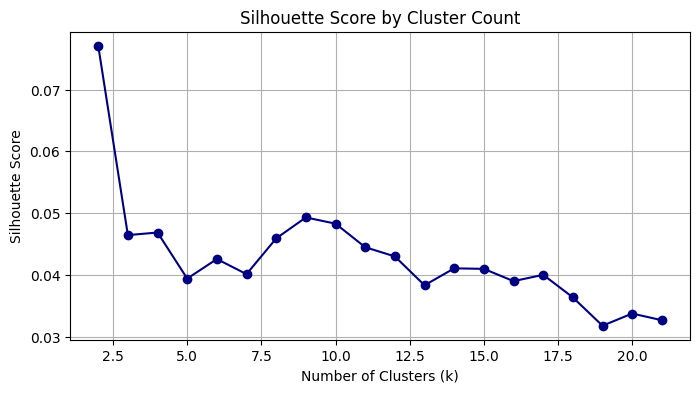

Optimizing Defense Clusters:


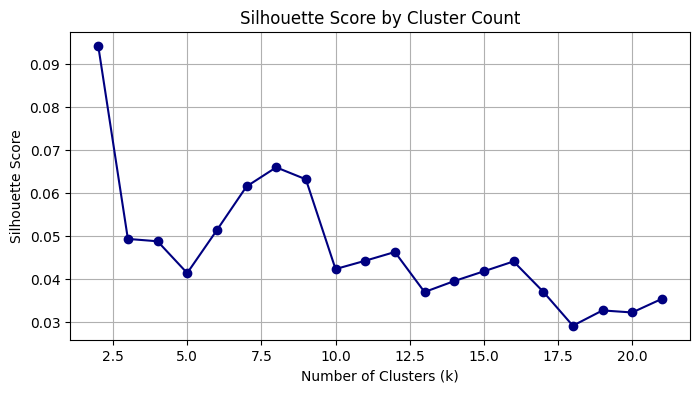

In [35]:
# Agglomerative Hierarchical Clustering (Ward’s Method)
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score

# Compute linkage matrices for offense and defense
off_data = off_roe_pca_df[[col for col in off_roe_pca_df.columns if col.startswith('ROE_PC')]].fillna(0)
def_data = def_roe_pca_df[[col for col in def_roe_pca_df.columns if col.startswith('ROE_PC')]].fillna(0)

def find_optimal_k(data, max_k=20):
    scores = []
    k_range = range(2, max_k + 2)
    
    for k in k_range:
        model = AgglomerativeClustering(n_clusters=k, linkage='ward')
        labels = model.fit_predict(data)
        score = silhouette_score(data, labels)
        scores.append(score)
        #print(f"Clusters: {k} | Silhouette Score: {score:.4f}")
    
    plt.figure(figsize=(8, 4))
    plt.plot(k_range, scores, marker='o', color='navy')
    plt.title('Silhouette Score by Cluster Count')
    plt.xlabel('Number of Clusters (k)')
    plt.ylabel('Silhouette Score')
    plt.grid(True)
    plt.show()

# Run it for offense
print("Optimizing Offense Clusters:")
find_optimal_k(off_data)

# Run it for defense
print("Optimizing Defense Clusters:")
find_optimal_k(def_data)

Offense Silhouette Score: 0.0771
Defense Silhouette Score: 0.0942


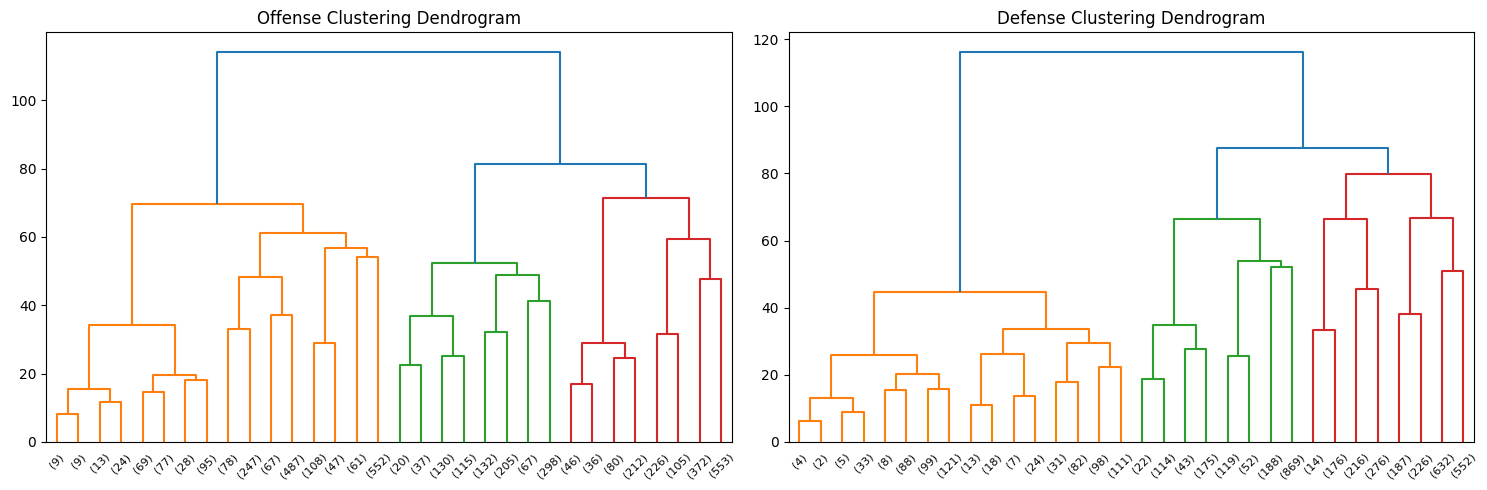

In [39]:
# Agglomerative Hierarchical Clustering (Ward’s Method)
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

# Compute linkage matrices for offense and defense
off_data = off_roe_pca_df[[col for col in off_roe_pca_df.columns if col.startswith('ROE_PC')]].fillna(0)
def_data = def_roe_pca_df[[col for col in def_roe_pca_df.columns if col.startswith('ROE_PC')]].fillna(0)

off_linkage = linkage(off_data, method='ward')
def_linkage = linkage(def_data, method='ward')

# Perform clustering
off_agg = AgglomerativeClustering(n_clusters=2, linkage='ward')
def_agg = AgglomerativeClustering(n_clusters=2, linkage='ward')

off_roe_pca_df['agglo_cluster'] = off_agg.fit_predict(off_data)
def_roe_pca_df['agglo_cluster'] = def_agg.fit_predict(def_data)

# Silhouette Scores
from sklearn.metrics import silhouette_score
off_silhouette = silhouette_score(off_data, off_agg.labels_)
def_silhouette = silhouette_score(def_data, def_agg.labels_)
print(f"Offense Silhouette Score: {off_silhouette:.4f}")
print(f"Defense Silhouette Score: {def_silhouette:.4f}")

# Show dendrograms for offense and defense
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
dendrogram(off_linkage, truncate_mode='level', p=4)
plt.title('Offense Clustering Dendrogram')
plt.subplot(1, 2, 2)
dendrogram(def_linkage, truncate_mode='level', p=4)
plt.title('Defense Clustering Dendrogram')
plt.tight_layout()
plt.show()

In [46]:
# Gaussian Mixture Models to identify scheme clusters
from sklearn.mixture import GaussianMixture
def fit_gmm(df, feature_cols, prefix):
    gmm = GaussianMixture(n_components=10, random_state=99)
    df[f'{prefix}_cluster'] = gmm.fit_predict(df[feature_cols].fillna(0))
    return gmm

off_gmm = fit_gmm(off_roe_pca_df, [col for col in off_roe_pca_df.columns if col.startswith('ROE_PC')], 'offense')
def_gmm = fit_gmm(def_roe_pca_df, [col for col in def_roe_pca_df.columns if col.startswith('ROE_PC')], 'defense')

off_gmm_df = off_roe_pca_df[['offensive_coach', 'game_id', 'offense_cluster']]
def_gmm_df = def_roe_pca_df[['defensive_coach', 'game_id', 'defense_cluster']]

# Silhouette Scores for GMM Clusters
off_gmm_silhouette = silhouette_score(off_roe_pca_df[[col for col in off_roe_pca_df.columns if col.startswith('ROE_PC')]].fillna(0), off_gmm_df['offense_cluster'])
def_gmm_silhouette = silhouette_score(def_roe_pca_df[[col for col in def_roe_pca_df.columns if col.startswith('ROE_PC')]].fillna(0), def_gmm_df['defense_cluster'])
print(f"Offense GMM Silhouette Score: {off_gmm_silhouette:.4f}")
print(f"Defense GMM Silhouette Score: {def_gmm_silhouette:.4f}")

Offense GMM Silhouette Score: -0.0131
Defense GMM Silhouette Score: -0.0199
